# Project 1: UBOS District Population Forecaster
**MSCS & MSDS OOP with Python — Advent 2026**

**Data notice:** All series are illustrative. Kampala, Wakiso and Gulu come from the assignment. Mbarara and Arua are synthetic demonstration data, not UBOS estimates. Population values are in **thousands**.

In [8]:
import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "src" / "population.py").is_file():
    project_root = project_root.parent

if not (project_root / "src" / "population.py").is_file():
    raise FileNotFoundError(
        f"Cannot find src/population.py. Current folder: {Path.cwd()}"
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project folder:", project_root)

Project folder: d:\MSDS\OOP\Assignment 2 mini project\project1_population


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from src.population import (DistrictPopulation, LinearForecaster, CAGRForecaster,
                            FibonacciForecaster, error_metrics, additional_classrooms,
                            bootstrap_intervals)
np.set_printoptions(precision=2, suppress=True)
YEARS = np.arange(2015, 2025)
raw_data = {
    'Kampala': [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    'Wakiso': [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    'Gulu': [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    'Mbarara': [310, 320, 335, 349, 365, 381, 399, 416, 436, 455],
    'Arua': [245, 252, 261, 269, 281, 294, 306, 320, 335, 351],
}
districts = [DistrictPopulation(name, YEARS, values) for name, values in raw_data.items()]
print(districts)


[DistrictPopulation(name='Kampala', years=2015–2024, n=10), DistrictPopulation(name='Wakiso', years=2015–2024, n=10), DistrictPopulation(name='Gulu', years=2015–2024, n=10), DistrictPopulation(name='Mbarara', years=2015–2024, n=10), DistrictPopulation(name='Arua', years=2015–2024, n=10)]


## 1. Descriptive statistics
`statistics.variance` uses sample variance (denominator *n−1*). NumPy defaults to population variance (denominator *n*). Set `ddof=1` to match the sample estimate.

In [11]:
stats_df = pd.DataFrame({d.name: d.descriptive_statistics() for d in districts}).T
print(stats_df.round(3).to_string())
assert np.allclose(stats_df['sample_variance_statistics'], stats_df['sample_variance_numpy'])


         mean_statistics  median_statistics  sample_variance_statistics  sample_std_statistics  mean_numpy  median_numpy  population_variance_numpy  sample_variance_numpy  sample_std_numpy
Kampala           1477.0             1460.0                   42601.111                206.400      1477.0        1460.0                   38341.00              42601.111           206.400
Wakiso            1280.0             1260.0                   60066.667                245.085      1280.0        1260.0                   54060.00              60066.667           245.085
Gulu               389.5              382.5                    2885.833                 53.720       389.5         382.5                    2597.25               2885.833            53.720
Mbarara            376.6              373.0                    2446.044                 49.458       376.6         373.0                    2201.44               2446.044            49.458
Arua               291.4              287.5            

## 2. Year-on-year growth and CAGR
Year-on-year growth = 100 × (P[t]−P[t−1])/P[t−1]. CAGR = (P[last]/P[first])^(1/9) − 1.

In [12]:
growth_df = pd.DataFrame({d.name: d.growth_rates() for d in districts}, index=YEARS[1:])
cagr_df = pd.DataFrame({'District': [d.name for d in districts],
                        'CAGR (%)': [100*d.cagr() for d in districts]})
print('Growth rates (%)\n', growth_df.round(2).to_string())
print('\nCAGR ranking\n', cagr_df.sort_values('CAGR (%)', ascending=False).round(2).to_string(index=False))
print('Fastest relative growth:', cagr_df.loc[cagr_df['CAGR (%)'].idxmax(), 'District'])


Growth rates (%)
       Kampala  Wakiso  Gulu  Mbarara  Arua
2016     4.17    5.26  3.12     3.23  2.86
2017     4.00    7.00  4.55     4.69  3.57
2018     3.85    7.48  4.35     4.18  3.07
2019     5.19    6.09  4.17     4.58  4.46
2020     5.63    6.56  4.00     4.38  4.63
2021     5.33    6.92  5.13     4.72  4.08
2022     4.43    6.47  4.88     4.26  4.58
2023     4.24    6.08  5.81     4.81  4.69
2024     4.65    6.37  5.49     4.36  4.78

CAGR ranking
 District  CAGR (%)
  Wakiso      6.47
 Kampala      4.61
    Gulu      4.61
 Mbarara      4.36
    Arua      4.08
Fastest relative growth: Wakiso


## 3. Fit three models and validate on 2022–2024
Fit only 2015–2021. Predict three future years and calculate MAE, RMSE and MAPE. Select the model with minimum RMSE; MAE and MAPE are secondary diagnostics.

In [13]:
model_types = {'Linear': LinearForecaster, 'CAGR': CAGRForecaster,
               'Fibonacci': FibonacciForecaster}
all_metrics = []
results = {}
for district in districts:
    train_years, train_pop = district.years[:7], district.populations[:7]
    test_years, test_pop = district.years[7:], district.populations[7:]
    fitted_models = {}
    for model_name, model_type in model_types.items():
        model = model_type().fit(train_years, train_pop)
        predicted = model.predict(3)
        metrics = error_metrics(test_pop, predicted)
        all_metrics.append({'District': district.name, 'Model': model_name, **metrics})
        fitted_models[model_name] = predicted
    results[district.name] = fitted_models
metrics_df = pd.DataFrame(all_metrics)
for district in districts:
    print('\n', district.name)
    print(metrics_df[metrics_df.District == district.name].sort_values('RMSE').round(2).to_string(index=False))
selected = (metrics_df.sort_values(['RMSE','MAE','Model'])
            .drop_duplicates('District').set_index('District')['Model'].to_dict())
print('\nSelected models:', selected)



 Kampala
District     Model     MAE    RMSE  MAPE (%)
 Kampala      CAGR    9.62   10.39      0.55
 Kampala    Linear   37.62   38.97      2.17
 Kampala Fibonacci 3543.33 4025.36    202.00

 Wakiso
District     Model    MAE    RMSE  MAPE (%)
  Wakiso      CAGR    6.8    8.05      0.42
  Wakiso    Linear   49.4   52.37      3.09
  Wakiso Fibonacci 3060.0 3479.87    189.87

 Gulu
District     Model    MAE    RMSE  MAPE (%)
    Gulu      CAGR   9.44   10.87      2.02
    Gulu    Linear  18.57   20.29      4.01
    Gulu Fibonacci 911.67 1035.64    196.04

 Mbarara
District     Model    MAE    RMSE  MAPE (%)
 Mbarara      CAGR   1.49    1.77      0.33
 Mbarara    Linear   9.56   10.25      2.17
 Mbarara Fibonacci 894.33 1015.98    201.61

 Arua
District     Model    MAE   RMSE  MAPE (%)
    Arua      CAGR   5.64   6.25      1.66
    Arua    Linear  11.51  12.29      3.39
    Arua Fibonacci 684.67 777.86    200.39

Selected models: {'Mbarara': 'CAGR', 'Arua': 'CAGR', 'Wakiso': 'CAGR', 'Kamp

## 4. Refit on 2015–2024 and forecast 2025–2029
Model selection uses the holdout data; after selection, the chosen model is refitted on all 10 observations.

In [14]:
forecast_years = np.arange(2025, 2030)
forecast_rows = []
forecasts = {}
intervals = {}
for district in districts:
    name = selected[district.name]
    model = model_types[name]().fit(district.years, district.populations)
    prediction = model.predict(5)
    forecasts[district.name] = prediction
    lo, hi = bootstrap_intervals(model_types[name], district.years, district.populations,
                                 horizon=5, n_boot=1000, seed=42)
    intervals[district.name] = (lo, hi)
    for year, value, lower, upper in zip(forecast_years, prediction, lo, hi):
        forecast_rows.append({'District': district.name, 'Year': year,
                              'Selected model': name, 'Forecast (000s)': value,
                              '95% lower (000s)': lower, '95% upper (000s)': upper})
forecast_df = pd.DataFrame(forecast_rows)
print(forecast_df.round(2).to_string(index=False))


District  Year Selected model  Forecast (000s)  95% lower (000s)  95% upper (000s)
 Kampala  2025           CAGR          1882.95           1876.15           1901.91
 Kampala  2026           CAGR          1969.72           1962.92           1988.68
 Kampala  2027           CAGR          2060.49           2053.69           2079.45
 Kampala  2028           CAGR          2155.44           2148.64           2174.40
 Kampala  2029           CAGR          2254.76           2247.97           2273.73
  Wakiso  2025           CAGR          1778.03           1771.26           1795.39
  Wakiso  2026           CAGR          1893.04           1886.27           1910.41
  Wakiso  2027           CAGR          2015.49           2008.72           2032.86
  Wakiso  2028           CAGR          2145.86           2139.10           2163.23
  Wakiso  2029           CAGR          2284.67           2277.91           2302.04
    Gulu  2025           CAGR           502.12            501.95            508.58
    

## 5. Variance comparison
The variance of a historical sequence versus a forecast sequence measures dispersion **across years**. It is not a direct measure of forecast uncertainty. The series have different lengths and trends.

In [15]:
variance_rows = []
for district in districts:
    variance_rows.append({'District': district.name,
                          'Historical variance (2015–2024)': np.var(district.populations, ddof=1),
                          'Forecast variance (2025–2029)': np.var(forecasts[district.name], ddof=1)})
variance_df = pd.DataFrame(variance_rows)
print(variance_df.round(2).to_string(index=False))


District  Historical variance (2015–2024)  Forecast variance (2025–2029)
 Kampala                         42601.11                       21607.68
  Wakiso                         60066.67                       40131.36
    Gulu                          2885.83                        1536.55
 Mbarara                          2446.04                        1218.40
    Arua                          1303.38                         626.12


## 6. Plot actual, holdout predictions and 2025–2029 forecasts
Dashed vertical line marks the 2021/2022 training/test boundary. Dotted vertical line marks the start of the forecast period. Shaded bands are exploratory residual-bootstrap intervals.

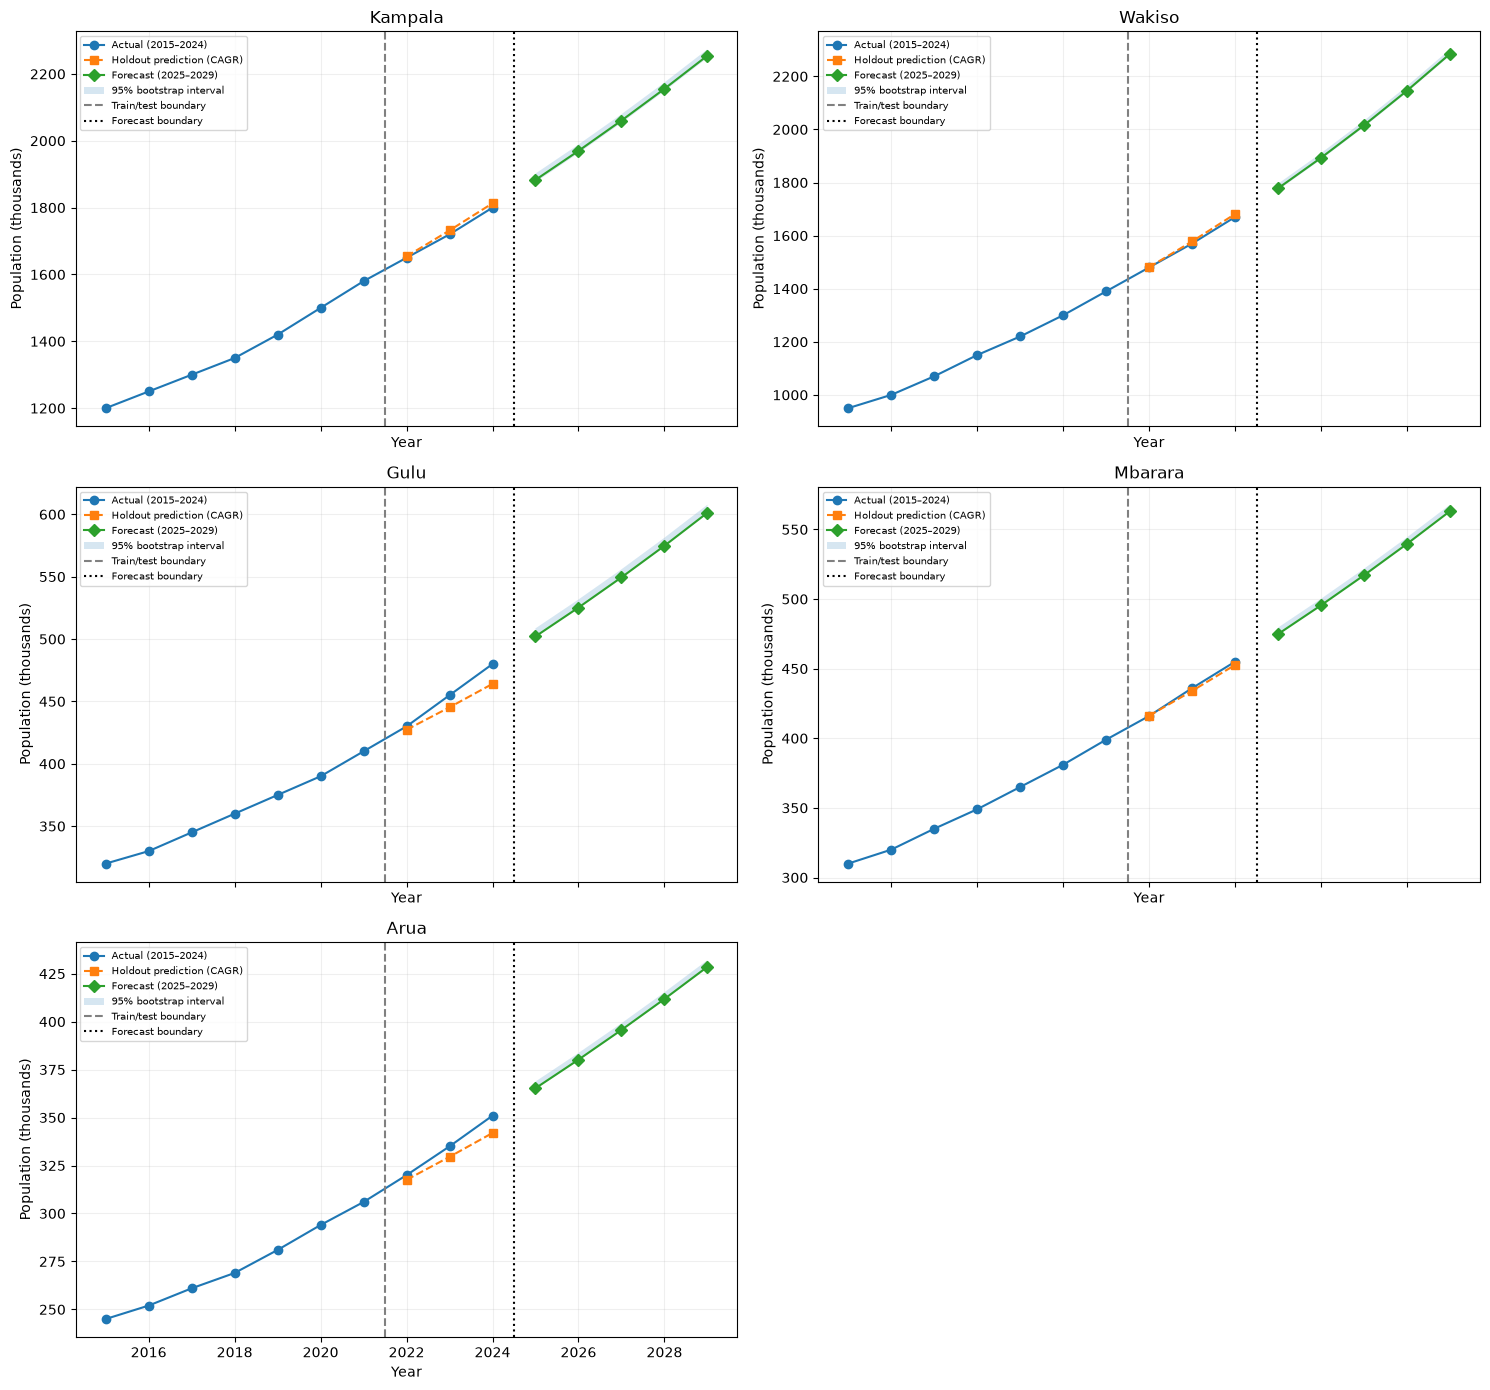

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(15, 14), sharex=True)
for ax, district in zip(axes.flat, districts):
    name = selected[district.name]
    ax.plot(district.years, district.populations, 'o-', label='Actual (2015–2024)')
    ax.plot(district.years[7:], results[district.name][name], 's--', label=f'Holdout prediction ({name})')
    ax.plot(forecast_years, forecasts[district.name], 'D-', label='Forecast (2025–2029)')
    lo, hi = intervals[district.name]
    ax.fill_between(forecast_years, lo, hi, alpha=0.18, label='95% bootstrap interval')
    ax.axvline(2021.5, color='gray', linestyle='--', label='Train/test boundary')
    ax.axvline(2024.5, color='black', linestyle=':', label='Forecast boundary')
    ax.set_title(district.name)
    ax.set_ylabel('Population (thousands)')
    ax.set_xlabel('Year')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7)
for ax in axes.flat[len(districts):]: ax.axis('off')
plt.tight_layout()
plt.show()


## 7. Estimate additional primary-school classrooms by 2029
Assume 18% of people are primary-school age and one classroom accommodates 53 pupils. These are **additional classrooms relative to estimated 2024 requirement**, not the actual district infrastructure shortfall.

In [17]:
classroom_rows = []
for district in districts:
    needs = additional_classrooms(district.populations[-1], forecasts[district.name][-1])
    classroom_rows.append({'District': district.name, **needs})
classroom_df = pd.DataFrame(classroom_rows)
print(classroom_df.to_string(index=False))


District  classrooms_2024  classrooms_2029  additional_classrooms
 Kampala             6114             7658                   1544
  Wakiso             5672             7760                   2088
    Gulu             1631             2043                    412
 Mbarara             1546             1913                    367
    Arua             1193             1456                    263


## 8. Critical discussion: Fibonacci-ratio model
The Fibonacci model has no demographic mechanism: its successive multiplicative factors converge to the golden ratio (approximately 1.618), implying roughly 61.8% annual growth. Such sustained growth is not realistic for district populations. Its results depend heavily on the starting ratio convention. It is useful only as an illustrative mathematical benchmark, not as a credible planning model. Linear and CAGR models also have limitations, especially with migration, administrative boundary changes and changing fertility or mortality.

## 9. Findings & Limitations (150–300 words)

**Replace this template with your own interpretation after running the notebook:**

The analysis compared five illustrative district population series over 2015–2024 and evaluated linear, CAGR and Fibonacci-ratio forecasting methods on a 2022–2024 holdout period. The district with the highest compound annual growth rate was **[insert district and calculated percentage]**. For **[insert district]**, the lowest test RMSE was obtained by **[insert model]**, indicating that it tracked the withheld observations more closely than the alternatives. Across districts, the selected methods **[describe the pattern observed in the comparison tables]**. The 2029 population forecasts imply additional classroom requirements of **[insert results]**, assuming 18% of residents are primary-school age and 53 pupils per classroom.

These estimates should not be interpreted as official district forecasts. The assignment series are illustrative, and the additional Mbarara and Arua series are synthetic. Only ten observations are available, so holdout evaluation is based on three years. Model rankings may change with a different test period. A further limitation is that the models ignore migration, changing district boundaries, births, deaths and policy changes. The Fibonacci method is particularly unrealistic because its multiplicative growth factor approaches approximately 1.618. The bootstrap intervals depend on historical residuals being reasonably representative of future errors. Finally, the classroom figures measure growth in estimated need relative to 2024; they do not measure existing classroom shortages. Better planning would require official population projections and actual school-capacity data.

## References and reproducibility
- MSCS & MSDS OOP with Python, Assignment 2, Advent 2026 (assignment-provided illustrative data).
- Replace synthetic districts with cited UBOS data if used for actual planning.
- All random resampling uses `np.random.default_rng(42)`.
- AI assistance: see README for disclosure.
- Run `python -m pytest -q` from the repository root.